In [42]:
# Generating Summary Statistics:

import pandas as pd

# Importing dataset:
dataset = pd.read_stata(
    r"C:\Users\jonat\OneDrive\Desktop\Uni\Gerber et al 2008\GerberGreenLarimer_APSR_2008_social_pressure.dta",
    convert_categoricals=False
)

# Creating four treatment dummy variables:
for t in range(1, 5):
    dataset[f"treatment_{t}"] = (
        dataset["treatment"] == t
    ).astype(int)

# Variables for descriptive statistics:
variables = [
    "voted",
    "treatment_1",
    "treatment_2",
    "treatment_3",
    "treatment_4",
    "hh_size",
    "g2004",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

# Compiling descriptive statistics table:
descriptive_stats = dataset[variables].describe().T

summary_table = descriptive_stats.rename(columns={
    "count": "N",
    "mean": "Mean",
    "50%": "Median",
    "std": "Standard Deviation",
    "min": "Minimum",
    "max": "Maximum"
})

# Addding missing-value counts:
summary_table["Missing N"] = dataset[variables].isna().sum()

# Displaying summary statistics:
display(summary_table.round(2))


# Selecting relevant descriptive statistics:
summary_table_compact = summary_table[
    ["N", "Mean", "Standard Deviation", "Minimum", "Maximum"]
].copy()

# Shortening column names:
summary_table_compact = summary_table_compact.rename(columns={
    "Standard Deviation": "SD",
    "Minimum": "Min",
    "Maximum": "Max"
})

# Formatting N as an integer:
summary_table_compact["N"] = summary_table_compact["N"].astype(int)

# Exporting to LaTeX:
summary_table_compact.to_latex(
    "summary_statistics.tex",
    index=True,
    caption="Descriptive Statistics",
    label="tab:summary_stats",
    float_format="%.2f",
    escape=True
)


# Creating separate missing-values table:
missing_table = summary_table[["Missing N"]].copy()

missing_table.to_latex(
    "Missing_values_results.tex",
    index=True,
    caption="Missing Values by Variable",
    label="tab:missing_values",
    escape=True
)

,N,Mean,Standard Deviation,Minimum,25%,Median,75%,Maximum,Missing N
voted,344084.0,0.32,0.46,0.0,0.0,0.0,1.0,1.0,0
treatment_1,344084.0,0.11,0.31,0.0,0.0,0.0,0.0,1.0,0
treatment_2,344084.0,0.11,0.31,0.0,0.0,0.0,0.0,1.0,0
treatment_3,344084.0,0.11,0.31,0.0,0.0,0.0,0.0,1.0,0
treatment_4,344084.0,0.11,0.31,0.0,0.0,0.0,0.0,1.0,0
hh_size,344084.0,2.18,0.79,1.0,2.0,2.0,2.0,8.0,0
g2004,344084.0,1.00,0.00,1.0,1.0,1.0,1.0,1.0,0
g2002,344084.0,0.81,0.39,0.0,1.0,1.0,1.0,1.0,0
g2000,344084.0,0.84,0.36,0.0,1.0,1.0,1.0,1.0,0
p2004,344084.0,0.40,0.49,0.0,0.0,0.0,1.0,1.0,0


                            OLS Regression Results                            
Dep. Variable:                  voted   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     2492.
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        17:59:03   Log-Likelihood:            -2.1033e+05
No. Observations:              344084   AIC:                         4.207e+05
Df Residuals:                  344071   BIC:                         4.208e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
treatment_1     0.0249      0.002      9.981      

C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.435e+04, tolerance: 1.087e+01
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_m

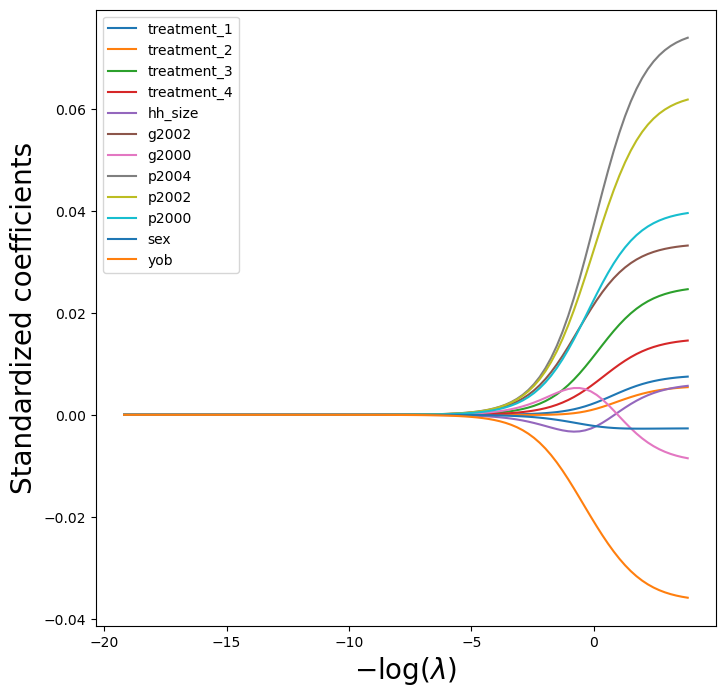

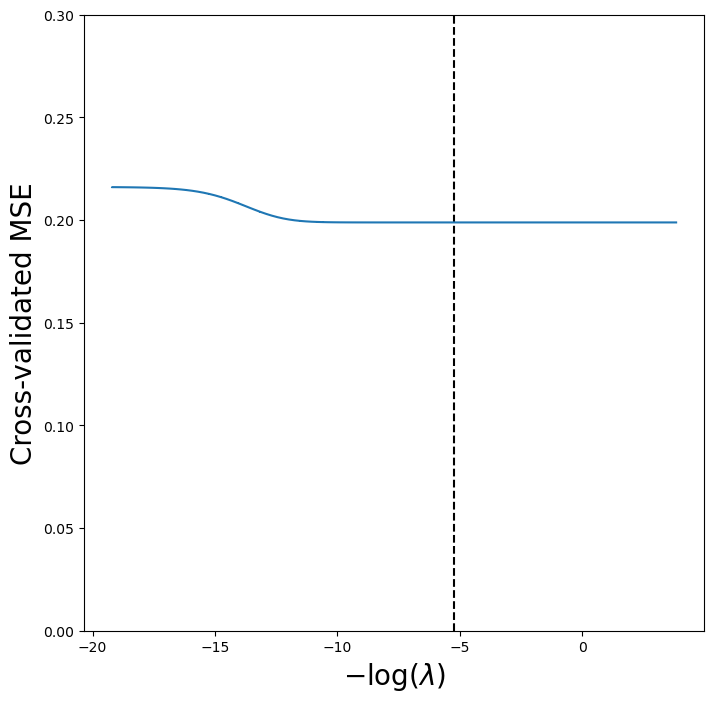

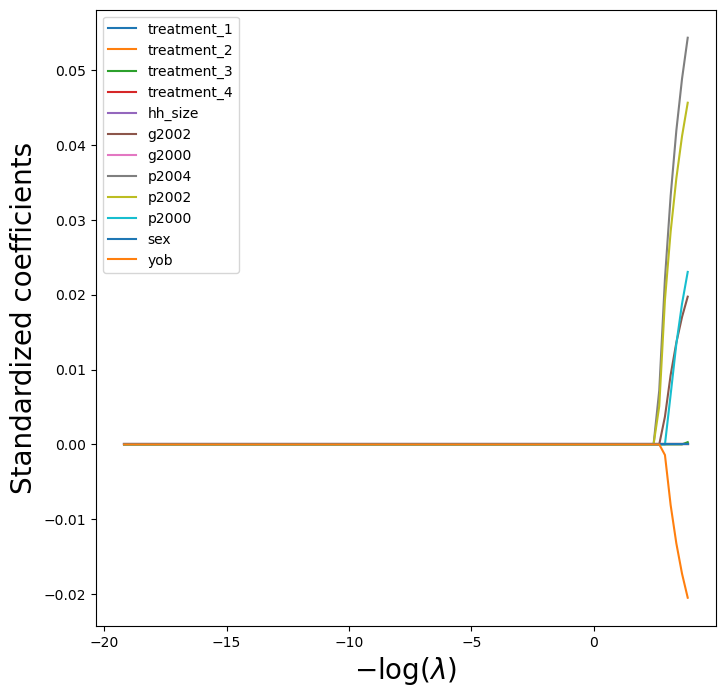

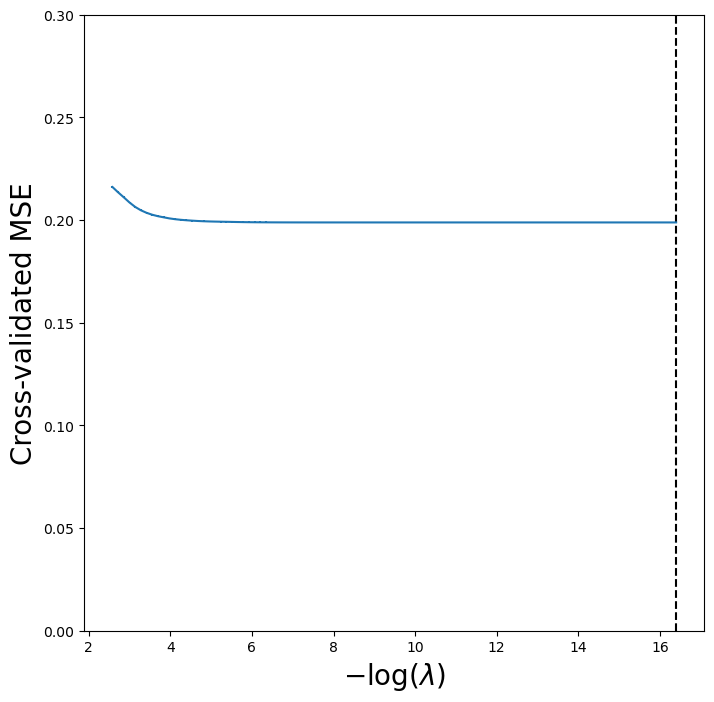

In [2]:
# Regularization Analyses:

# Importing data analysis packages:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.api import OLS
from ISLP.models import ModelSpec as MS
import sklearn.linear_model as skl
from matplotlib.pyplot import subplots
from ISLP.models import \
     (Stepwise,
      sklearn_selected,
      sklearn_selection_path)
import sklearn.model_selection as skm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Defining treatment dummy variables and add them back into dataset:

dataset["treatment"] = dataset["treatment"].astype(int)
treatment_dummies = pd.get_dummies(dataset['treatment'], prefix='treatment', dtype=int)
dataset = pd.concat([dataset, treatment_dummies], axis=1)

# Defining variables for analysis:

variables = [
    "voted",
    "treatment_1",
    "treatment_2",
    "treatment_3",
    "treatment_4",
    "hh_size",
    "g2004",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

# Setting up OLS model:

Y = dataset["voted"]
X = dataset[variables[1:]]
X = sm.add_constant(X)

# Running OLS Model:

OLS_Model = sm.OLS(Y,X).fit()
print(OLS_Model.summary())

# Generating the LaTeX output for the regression table:
print(OLS_Model.summary().as_latex())

# Ridge Regression:

# Creating predictor list, dropping g2004 due to having zero variance:

predictors = [
    "treatment_1",
    "treatment_2",
    "treatment_3",
    "treatment_4",
    "hh_size",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

#Making two graphs:

design = MS(predictors).fit(dataset)

D = design.fit_transform(dataset)
D = D.drop('intercept', axis=1)
X = np.asarray(D)

Xs = X - X.mean(0)[None,:]
X_scale = X.std(0)
Xs = Xs/ X_scale[None,:]
lambdas = 10**np.linspace(8, -2, 100) / Y.std()
soln_array = skl.ElasticNet.path(Xs,
                                 Y,
                                 l1_ratio=0.,
                                 alphas=lambdas)[1]

soln_path = pd.DataFrame(soln_array.T,
                         columns=D.columns,
                         index=-np.log(lambdas))
soln_path.index.name = 'negative log(lambda)'


path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left');  

ridgeCV = skl.RidgeCV(alphas=lambdas, store_cv_results=True)

pipeCV = Pipeline([
    ('ridge', ridgeCV)
])

pipeCV.fit(Xs, Y)

tuned_ridge = pipeCV.named_steps['ridge']
ridgeCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(
    -np.log(lambdas),
    tuned_ridge.cv_results_.mean(0),
    yerr=tuned_ridge.cv_results_.std(0) / np.sqrt(len(Y))
)
ax.axvline(-np.log(tuned_ridge.alpha_), c='k', ls='--')
ax.set_ylim([0,0.3])
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

# LASSO Regression:

D = design.fit_transform(dataset)
D = D.drop('intercept', axis=1)
X = np.asarray(D)

lasso_soln_array = skl.ElasticNet.path(
    Xs,
    Y,
    l1_ratio=1.,
    alphas=lambdas
)[1]

soln_path = pd.DataFrame(lasso_soln_array.T,
                         columns=D.columns,
                         index=-np.log(lambdas))
soln_path.index.name = 'negative log(lambda)'
soln_path

path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left');

K = 5
kfold = skm.KFold(K,
                  random_state=0,
                  shuffle=True)

scaler = StandardScaler(with_mean=True,  with_std=True)

lassoCV = skl.ElasticNetCV(n_alphas=100,
                           eps=1e-6,
                           l1_ratio=1,
                           cv=kfold)
pipeCV = Pipeline(steps=[('scaler', scaler),
                         ('lasso', lassoCV)])
pipeCV.fit(X, Y)
tuned_lasso = pipeCV.named_steps['lasso']
tuned_lasso.alpha_

lassoCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(tuned_lasso.alphas_),
            tuned_lasso.mse_path_.mean(1),
            yerr=tuned_lasso.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_lasso.alpha_), c='k', ls='--')
ax.set_ylim([0,0.3])
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

# Creating a regression comparison table:

# Extracting coefficients from each model:

ols_coefs = OLS_Model.params.reindex(predictors)

ridge_coefs = pd.Series(
    tuned_ridge.coef_,
    index=predictors
)

lasso_coefs = pd.Series(
    tuned_lasso.coef_,
    index=predictors
)

# Combining coefficients into one table:

regularization_table = pd.DataFrame({
    "Ridge": ridge_coefs,
    "LASSO": lasso_coefs
})

# Converting table to latex:

regularization_table.to_latex(
    "regularization_results.tex",
    index=True,
    caption="Comparison of OLS, Ridge, and LASSO Regression Coefficients",
    label="tab:regularization",
    float_format="%.4f",
    escape=True
)

In [21]:
# Extracting regression results:

ols_table = pd.DataFrame({
    "Coefficient": OLS_Model.params,
    "Std. Error": OLS_Model.bse,
    "t-statistic": OLS_Model.tvalues,
    "p-value": OLS_Model.pvalues
})

# Rounding values:
ols_table = ols_table.round(4)

# Exporting to latex:

regularization_table.to_latex(
    "regularization_results.tex",
    index=True,
    caption="Comparison of OLS, Ridge, and LASSO Regression Coefficients",
    label="tab:regularization",
    float_format="%.6f",
    escape=True
)

,Ridge,LASSO
treatment_1,0.007827,0.007836
treatment_2,0.005724,0.005732
treatment_3,0.025288,0.025305
treatment_4,0.015032,0.015044
hh_size,0.006209,0.006223
g2002,0.033636,0.033648
g2000,-0.009400,-0.009424
p2004,0.075598,0.075642
p2002,0.063152,0.063186
p2000,0.040266,0.040284


,Coefficient,Std. Error,t-statistic,p-value
treatment_1,0.0249,0.0025,9.9815,0.0000
treatment_2,0.0182,0.0025,7.3014,0.0000
treatment_3,0.0805,0.0025,32.2331,0.0000
treatment_4,0.0479,0.0025,19.1627,0.0000
hh_size,0.0079,0.0010,7.6721,0.0000
g2004,5.0550,0.1167,43.3132,0.0000
g2002,0.0860,0.0022,38.8434,0.0000
g2000,-0.0259,0.0024,-10.7886,0.0000
p2004,0.1543,0.0016,98.6543,0.0000
p2002,0.1296,0.0016,79.8807,0.0000


In [4]:
# Importing packages for regression trees:

import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
import sklearn.model_selection as skm
from ISLP import load_data, confusion_table
from ISLP.models import ModelSpec as MS

from sklearn.tree import (DecisionTreeClassifier as DTC,
                          DecisionTreeRegressor as DTR,
                          plot_tree,
                          export_text)
from sklearn.metrics import (accuracy_score,
                             log_loss)
from sklearn.ensemble import \
     (RandomForestRegressor as RF,
      GradientBoostingRegressor as GBR)
from ISLP.bart import BART

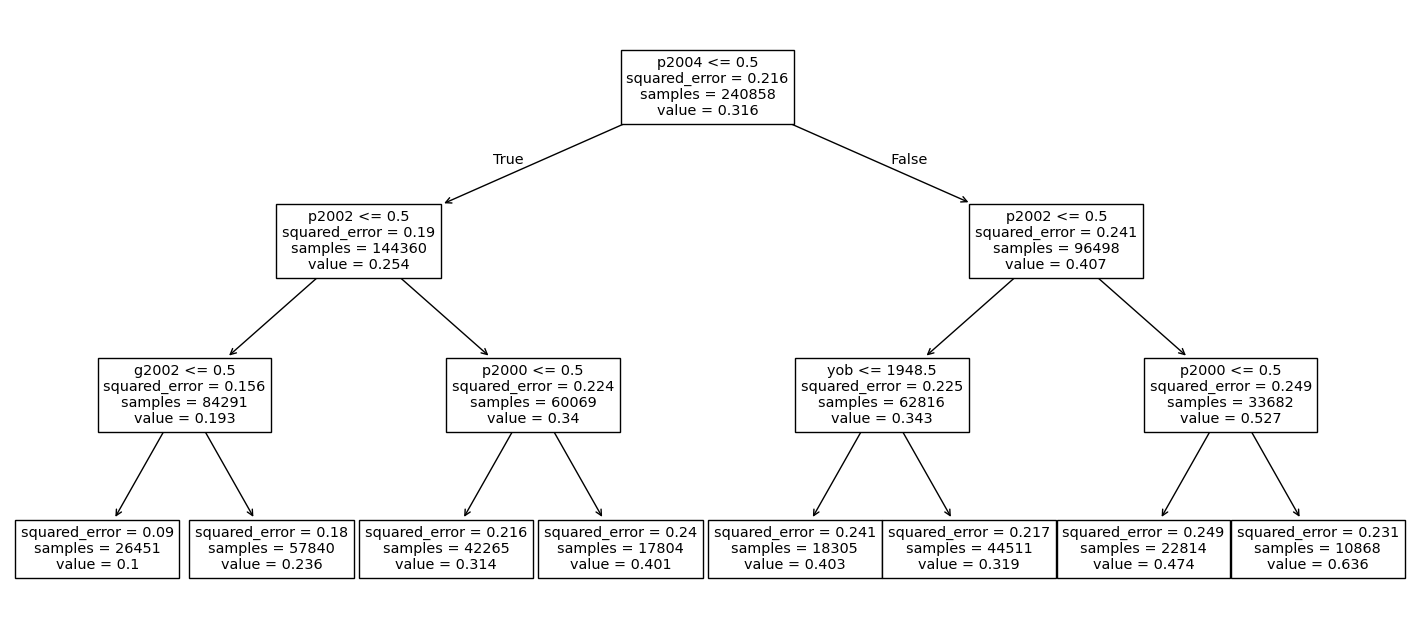

In [5]:
# Fitting Regression Trees

model = MS(dataset.columns.drop(['voted', 'hh_id', 'cluster']), intercept=False)
D = model.fit_transform(dataset)
feature_names = list(D.columns)
X = np.asarray(D)

(X_train,
 X_test,
 y_train,
 y_test) = skm.train_test_split(X,
                                dataset['voted'],
                                test_size=0.3,
                                random_state=0)

reg = DTR(max_depth=3)
reg.fit(X_train, y_train)
ax = subplots(figsize=(18,8))[1]
plot_tree(reg,
          feature_names=feature_names,
          ax=ax);

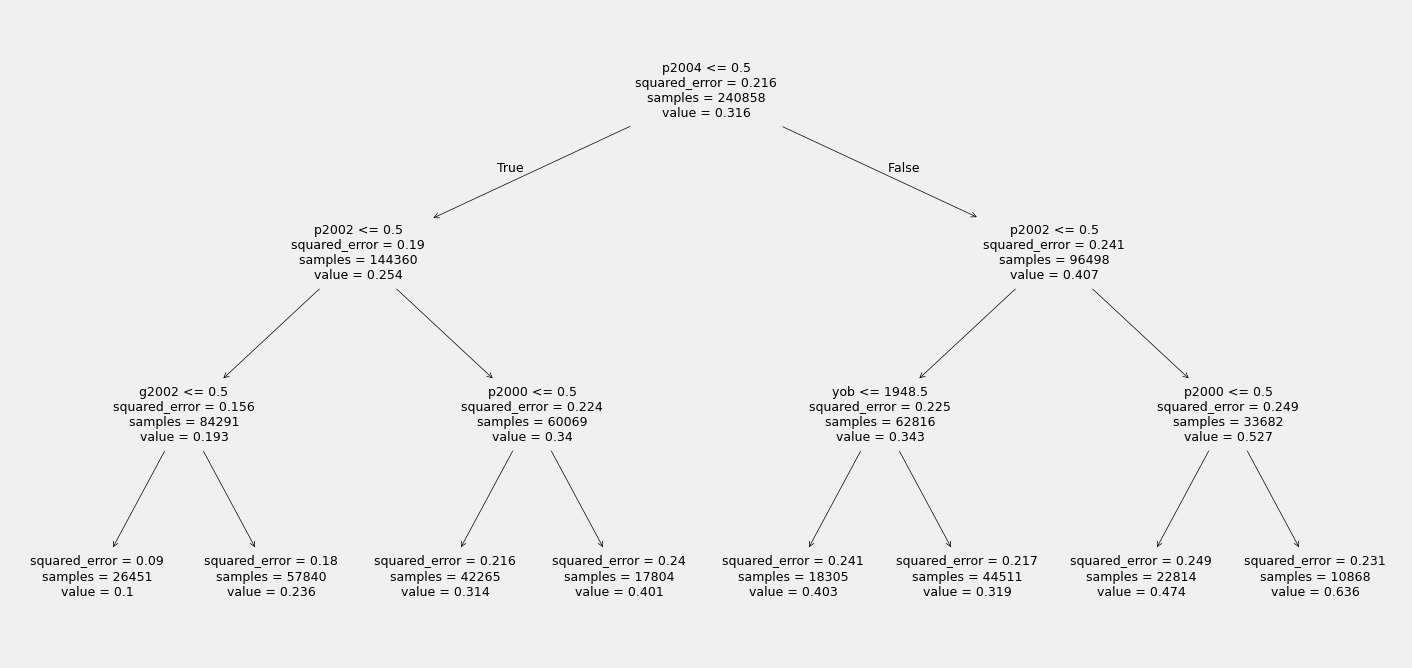

In [25]:
# Exporting regression tree

import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

fig, ax = plt.subplots(figsize=(16, 8))

plot_tree(
    reg,
    feature_names=feature_names,
    filled=False,
    rounded=False,
    proportion=False,
    impurity=True,
    label="all",
    fontsize=9,
    precision=3,
    ax=ax
)

ax.set_axis_off()

plt.savefig(
    "regression_tree.pdf",
    bbox_inches="tight",
    facecolor="white",
    dpi=300
)

plt.show()

In [ ]:
# Random Forest Model

RF_voted = RF(max_features=6,
               random_state=0).fit(X_train, y_train)
y_hat_RF = RF_voted.predict(X_test)
np.mean((y_test - y_hat_RF)**2)

feature_imp = pd.Dat

# Implementing random forest feature importance:

aFrame(
    {'Importance': RF_voted.feature_importances_},
    index=feature_names
)

feature_imp = feature_imp.sort_values(
    by='Importance',
    ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

feature_imp.plot.barh(
    y='Importance',
    ax=ax,
    legend=False
)

ax.set_xlabel("Feature Importance (Mean Decrease in Impurity)")
ax.set_ylabel("Predictor")
ax.set_title("Random Forest Feature Importance")

plt.tight_layout()
plt.savefig("random_forest_importance.pdf", bbox_inches="tight")
plt.show()

Boosting Error:
0.19686000810268242
Tree Error:
0.2009818486054303
Bagging Error:
0.23605209392209503
Random Forest Error:
0.23675169137403107


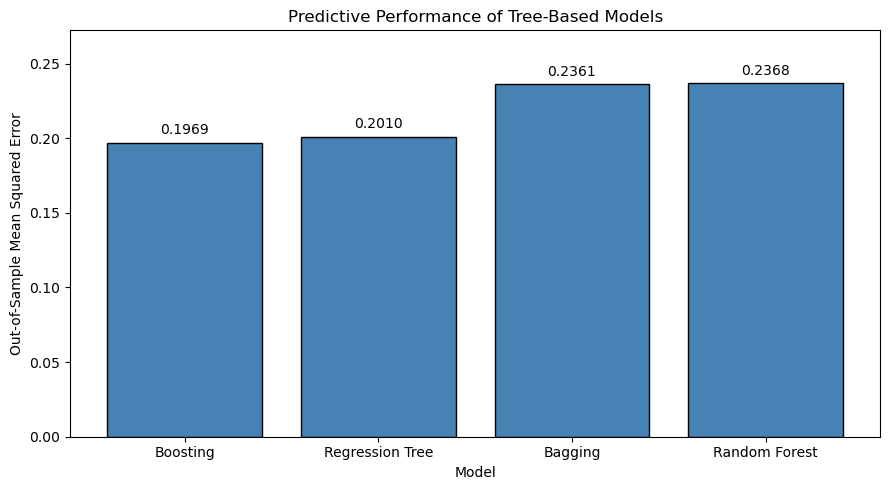

In [8]:
# Boosting Error

boost_data = GBR(n_estimators=100,
                   learning_rate=0.1,
                   max_depth=3,
                   random_state=0)
boost_data.fit(X_train, y_train)

y_hat_boost = boost_data.predict(X_test);

print("Boosting Error:")
print(np.mean((y_test - y_hat_boost)**2))

# Tree Error

ccp_path = reg.cost_complexity_pruning_path(X_train, y_train)
kfold = skm.KFold(5,
                  shuffle=True,
                  random_state=10)
grid = skm.GridSearchCV(reg,
                        {'ccp_alpha': ccp_path.ccp_alphas},
                        refit=True,
                        cv=kfold,
                        scoring='neg_mean_squared_error')
G = grid.fit(X_train, y_train)

best_ = grid.best_estimator_

print("Tree Error:")
print(np.mean((y_test - best_.predict(X_test))**2))

# Bagging Error

bag_data = RF(max_features=X_train.shape[1], random_state=0)
bag_data.fit(X_train, y_train)

y_hat_bag = bag_data.predict(X_test)

print("Bagging Error:")
print(np.mean((y_test - y_hat_bag)**2))

# Random Forest Error

RF_data = RF(max_features=6,
               random_state=0).fit(X_train, y_train)
y_hat_RF = RF_data.predict(X_test)

print("Random Forest Error:")
print(np.mean((y_test - y_hat_RF)**2))

# Generate bar chart comparing four models:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Calculate test MSE for all four models

model_errors = {
    "Regression Tree": np.mean((y_test - best_.predict(X_test))**2),
    "Bagging": np.mean((y_test - bag_data.predict(X_test))**2),
    "Random Forest": np.mean((y_test - RF_data.predict(X_test))**2),
    "Boosting": np.mean((y_test - boost_data.predict(X_test))**2)
}

# Create DataFrame

errors_df = pd.DataFrame(
    list(model_errors.items()),
    columns=["Model", "Test MSE"]
)

# Sort models by lowest MSE

errors_df = errors_df.sort_values("Test MSE")

# Create graph

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    errors_df["Model"],
    errors_df["Test MSE"],
    color="steelblue",
    edgecolor="black"
)

# Display exact MSE above each bar

for bar in bars:
    height = bar.get_height()
    ax.annotate(
        f"{height:.4f}",
        xy=(bar.get_x() + bar.get_width()/2, height),
        xytext=(0, 4),
        textcoords="offset points",
        ha="center",
        va="bottom"
    )

ax.set_ylabel("Out-of-Sample Mean Squared Error")
ax.set_xlabel("Model")
ax.set_title("Predictive Performance of Tree-Based Models")

ax.set_ylim(0, errors_df["Test MSE"].max() * 1.15)

plt.tight_layout()

# Export to PDF for LaTeX

plt.savefig("tree_model_comparison.pdf", bbox_inches="tight")

plt.show()

# Generate table:

errors_df.to_latex(
    "tree_model_comparison.tex",
    index=False,
    caption="Out-of-Sample Prediction Errors Across Tree-Based Models",
    label="tab:tree_comparison",
    float_format="%.5f"
)

In [9]:
from matplotlib.pyplot import subplots
import sklearn.model_selection as skm
from ISLP import load_data, confusion_table
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

import graphviz

# Make the simulation reproducible and create the image output folder.
np.random.seed(42)
Path('img').mkdir(exist_ok=True)

COLORS = [
    '#00B0F0',
    '#FF0000',
    '#B0F000'
]

Graph saved to: C:\Users\jonat\img\DAG_Experiment.png


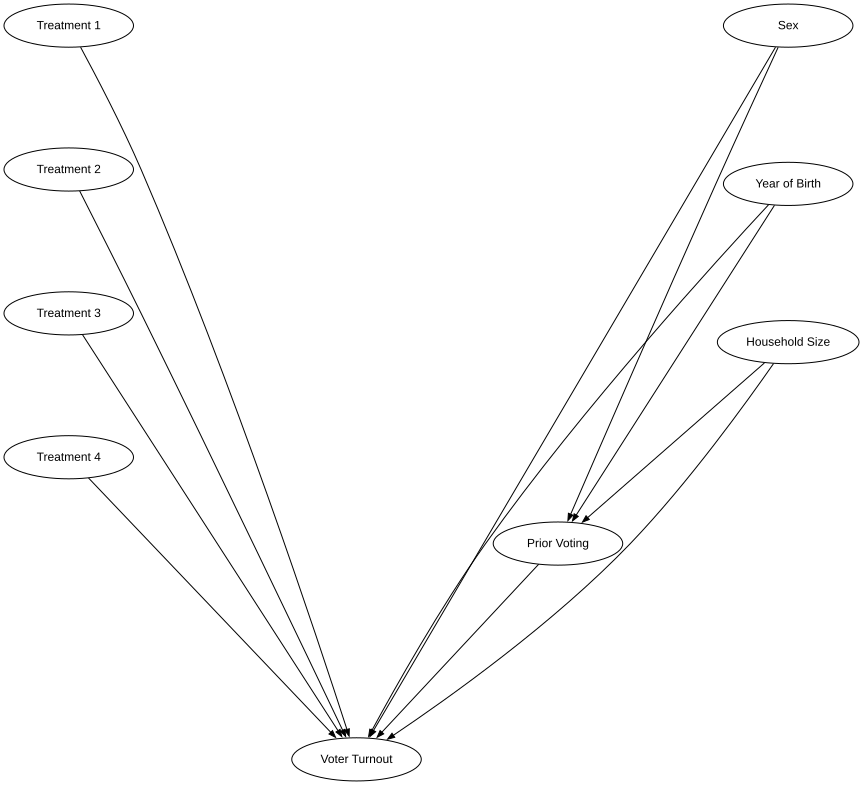

In [40]:
# DAG 1 - The Experiment

import graphviz
import os

# Creating output folder:
os.makedirs("img", exist_ok=True)

# Making DAG graph:
graph = graphviz.Digraph(
    format="png",
    engine="neato"
)

# Graph settings:
graph.attr(
    overlap="true",
    splines="true",
    outputorder="edgesfirst"
)

# Node settings:
graph.attr(
    "node",
    shape="ellipse",
    fontsize="12",
    fontname="Arial",
    width="1.8",
    height="0.6",
    margin="0.15,0.10",
    fixedsize="false"
)

# Edge settings:
graph.attr(
    "edge",
    arrowsize="0.7",
    penwidth="1.0"
)

# Defining nodes and positions:
positions = {
    "treatment_1": "0,9!",
    "treatment_2": "0,7!",
    "treatment_3": "0,5!",
    "treatment_4": "0,3!",
    "sex": "10,9!",
    "yob": "10,6.8!",
    "hh_size": "10,4.6!",
    "prior_voting": "6.8,1.8!",
    "Y": "4,-1.2!"
}

# Defining readable labels:
labels = {
    "treatment_1": "Treatment 1",
    "treatment_2": "Treatment 2",
    "treatment_3": "Treatment 3",
    "treatment_4": "Treatment 4",
    "sex": "Sex",
    "yob": "Year of Birth",
    "hh_size": "Household Size",
    "prior_voting": "Prior Voting",
    "Y": "Voter Turnout"
}

# Creating nodes:
for node, pos in positions.items():
    graph.node(
        node,
        label=labels[node],
        pos=pos,
        pin="true"
    )

# Defining causal relationships:
edges = [
    ("treatment_1", "Y"),
    ("treatment_2", "Y"),
    ("treatment_3", "Y"),
    ("treatment_4", "Y"),
    ("sex", "Y"),
    ("sex", "prior_voting"),
    ("yob", "Y"),
    ("yob", "prior_voting"),
    ("hh_size", "Y"),
    ("hh_size", "prior_voting"),
    ("prior_voting", "Y")
]

# Adding arrows:
for source, target in edges:
    graph.edge(source, target)

# Exporting image:
output_path = graph.render(
    "img/DAG_Experiment",
    cleanup=True
)

Graph saved to: C:\Users\jonat\img\DAG_Experiment_Household.png


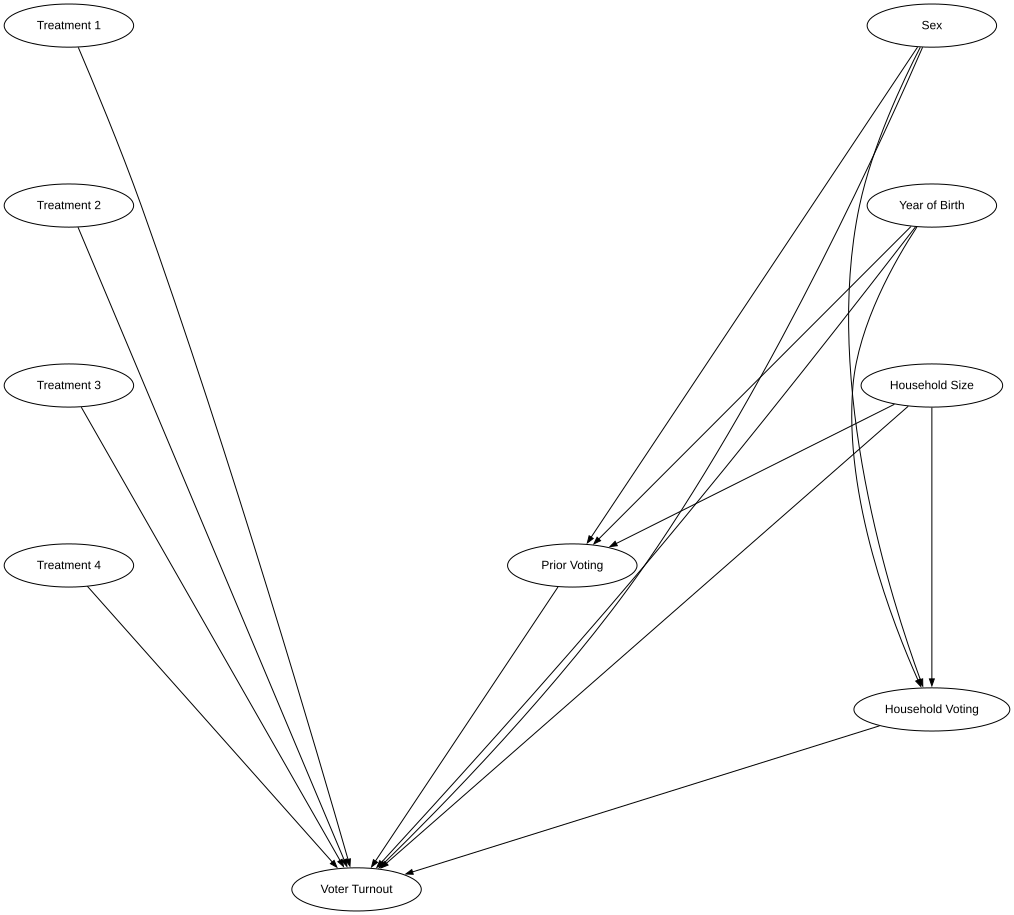

In [41]:
# DAG 2 - The Experiment with Household Voting:
graph = graphviz.Digraph(
    format="png",
    engine="neato"
)

# Graph settings:
graph.attr(
    overlap="true",
    splines="true",
    outputorder="edgesfirst"
)

# Node settings:
graph.attr(
    "node",
    shape="ellipse",
    fontsize="12",
    fontname="Arial",
    width="1.8",
    height="0.6",
    margin="0.15,0.10",
    fixedsize="false"
)

# Edge settings:
graph.attr(
    "edge",
    arrowsize="0.7",
    penwidth="1.0"
)

# Revised node positions:
positions = {
    "treatment_1": "0,10!",
    "treatment_2": "0,7.5!",
    "treatment_3": "0,5!",
    "treatment_4": "0,2.5!",
    "sex": "12,10!",
    "yob": "12,7.5!",
    "hh_size": "12,5!",
    "prior_voting": "7,2.5!",
    "household_voting": "12,0.5!",
    "Y": "4,-2!"
}

# Defining readable labels:
labels = {
    "treatment_1": "Treatment 1",
    "treatment_2": "Treatment 2",
    "treatment_3": "Treatment 3",
    "treatment_4": "Treatment 4",
    "sex": "Sex",
    "yob": "Year of Birth",
    "hh_size": "Household Size",
    "prior_voting": "Prior Voting",
    "household_voting": "Household Voting",
    "Y": "Voter Turnout"
}

# Creating nodes:
for node, pos in positions.items():
    graph.node(
        node,
        label=labels[node],
        pos=pos,
        pin="true"
    )

# Defining causal relationships:
edges = [
    # Treatment effects
    ("treatment_1", "Y"),
    ("treatment_2", "Y"),
    ("treatment_3", "Y"),
    ("treatment_4", "Y"),

    # Direct effects on voter turnout
    ("sex", "Y"),
    ("yob", "Y"),
    ("hh_size", "Y"),
    ("prior_voting", "Y"),
    ("household_voting", "Y"),

    # Effects on prior voting
    ("sex", "prior_voting"),
    ("yob", "prior_voting"),
    ("hh_size", "prior_voting"),

    # Effects on household voting
    ("sex", "household_voting"),
    ("yob", "household_voting"),
    ("hh_size", "household_voting")
]

# Adding arrows:
for source, target in edges:
    graph.edge(source, target)

# Exporting PNG:
output_path = graph.render(
    "img/DAG_Experiment_Household",
    cleanup=True
)

In [11]:
# Covariate Balance Table

import pandas as pd

# Baseline covariates
balance_vars = [
    "hh_size",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

# Calculate group means
balance_table = dataset.groupby("treatment")[balance_vars].mean().T

# Rename columns
balance_table.columns = [
    "Control",
    "Civic Duty",
    "Hawthorne",
    "Self",
    "Neighbors"
]

# Rename rows
balance_table.index = [
    "Household Size",
    "General Election 2002",
    "General Election 2000",
    "Primary Election 2004",
    "Primary Election 2002",
    "Primary Election 2000",
    "Male",
    "Year of Birth"
]

# Display table
display(balance_table.round(3))

# Export to LaTeX
balance_table.to_latex(
    "balance_table.tex",
    index=True,
    caption="Baseline Covariate Balance Across Experimental Groups",
    label="tab:balance",
    float_format="%.3f",
    escape=True
)

,Control,Civic Duty,Hawthorne,Self,Neighbors
Household Size,2.184,2.180,2.189,2.188,2.181
General Election 2002,0.811,0.813,0.811,0.811,0.811
General Election 2000,0.843,0.844,0.842,0.842,0.840
Primary Election 2004,0.400,0.403,0.399,0.407,0.402
Primary Election 2002,0.389,0.394,0.389,0.387,0.392
Primary Election 2000,0.252,0.250,0.254,0.251,0.251
Male,0.499,0.499,0.500,0.500,0.500
Year of Birth,1956.186,1956.295,1956.341,1956.147,1956.207


In [12]:
# Creating new household voting variable:

import pandas as pd
import numpy as np

# Previous elections
elections = [
    "g2004",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000"
]

# Verify that each individual appears only once
assert dataset["hh_id"].notna().all()

if "sex" in dataset.columns:
    pass  # No demographic restriction is required

# Generate household voting variables
for election in elections:

    # Total number of voters in each household
    household_total = dataset.groupby("hh_id")[election].transform("sum")

    # Exclude the individual's own voting behavior
    other_voters = household_total - dataset[election]

    # Number of other household members who voted
    dataset[f"household_voting_count_{election}"] = other_voters

    # Indicator: at least one other household member voted
    dataset[f"household_voting_{election}"] = (
        other_voters > 0
    ).astype(int)

# Display newly created variables
new_variables = [
    col for col in dataset.columns
    if col.startswith("household_voting")
]

display(dataset[["hh_id"] + elections + new_variables].head(15))

,hh_id,g2004,g2002,g2000,p2004,p2002,p2000,household_voting_count_g2004,household_voting_g2004,household_voting_count_g2002,household_voting_g2002,household_voting_count_g2000,household_voting_g2000,household_voting_count_p2004,household_voting_p2004,household_voting_count_p2002,household_voting_p2002,household_voting_count_p2000,household_voting_p2000
0,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1,1.0,1,1.0,1,0.0,0,1.0,1,0.0,0
1,1.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1,1.0,1,1.0,1,0.0,0,1.0,1,0.0,0
2,2.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,1,2.0,1,2.0,1,0.0,0,2.0,1,0.0,0
3,2.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,1,2.0,1,2.0,1,0.0,0,2.0,1,0.0,0
4,2.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,1,2.0,1,2.0,1,0.0,0,2.0,1,0.0,0
5,3.0,1.0,0.0,0.0,0.0,0.0,0.0,2.0,1,2.0,1,2.0,1,0.0,0,2.0,1,0.0,0
6,3.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,1,1.0,1,1.0,1,0.0,0,1.0,1,0.0,0
7,3.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,1,1.0,1,1.0,1,0.0,0,1.0,1,0.0,0
8,4.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,1,1.0,1,1.0,1,0.0,0,1.0,1,0.0,0
9,4.0,1.0,1.0,1.0,0.0,1.0,0.0,1.0,1,0.0,0,0.0,0,0.0,0,1.0,1,0.0,0


In [13]:
# Summary statistics for new variables:
display(dataset[new_variables].describe().T)

,count,mean,std,min,25%,50%,75%,max
household_voting_count_g2004,344084.0,1.184019,0.790658,0.0,1.0,1.0,1.0,7.0
household_voting_g2004,344084.0,0.860982,0.345966,0.0,1.0,1.0,1.0,1.0
household_voting_count_g2002,344084.0,0.898237,0.653004,0.0,1.0,1.0,1.0,6.0
household_voting_g2002,344084.0,0.753104,0.431206,0.0,1.0,1.0,1.0,1.0
household_voting_count_g2000,344084.0,0.931781,0.634773,0.0,1.0,1.0,1.0,5.0
household_voting_g2000,344084.0,0.782666,0.412432,0.0,1.0,1.0,1.0,1.0
household_voting_count_p2004,344084.0,0.446391,0.652190,0.0,0.0,0.0,1.0,6.0
household_voting_p2004,344084.0,0.372618,0.483502,0.0,0.0,0.0,1.0,1.0
household_voting_count_p2002,344084.0,0.425126,0.614417,0.0,0.0,0.0,1.0,6.0
household_voting_p2002,344084.0,0.367076,0.482008,0.0,0.0,0.0,1.0,1.0


In [14]:
# Creating treatment x household voting interactions:

interaction_predictors = []

for t in range(1, 5):
    for election in [
        "g2002", "g2000",
        "p2004", "p2002", "p2000"
    ]:
        interaction_name = f"treatment_{t}_X_household_{election}"

        dataset[interaction_name] = (
            dataset[f"treatment_{t}"] *
            dataset[f"household_voting_{election}"]
        )

        interaction_predictors.append(interaction_name)

# Original regression predictors
original_predictors = [
    "treatment_1",
    "treatment_2",
    "treatment_3",
    "treatment_4",
    "hh_size",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

# Household voting predictors
household_predictors = [
    "household_voting_g2002",
    "household_voting_g2000",
    "household_voting_p2004",
    "household_voting_p2002",
    "household_voting_p2000"
]

# Assembling regression predictors:
all_predictors = (
    original_predictors
    + household_predictors
    + interaction_predictors
)

Y = dataset["voted"]
X = sm.add_constant(dataset[all_predictors])

# Estimating OLS with household-clustered standard errors:
OLS_Interaction = sm.OLS(Y, X).fit(
    cov_type="cluster",
    cov_kwds={"groups": dataset["hh_id"]}
)

print(OLS_Interaction.summary())

# Extracting regression results:

ols_interaction_table = pd.DataFrame({
    "Coefficient": OLS_Interaction.params,
    "Std. Error": OLS_Interaction.bse,
    "t-statistic": OLS_Interaction.tvalues,
    "p-value": OLS_Interaction.pvalues
})

# Rounding values:
ols_interaction_table = ols_interaction_table.round(4)

# Exporting to LaTeX:
ols_interaction_table.to_latex(
    "OLS_interaction_results.tex",
    index=True,
    caption="OLS Regression Results with Household Voting Interactions",
    label="tab:ols_interaction_results",
    float_format="%.4f",
    escape=True
)

                            OLS Regression Results                            
Dep. Variable:                  voted   R-squared:                       0.081
Model:                            OLS   Adj. R-squared:                  0.081
Method:                 Least Squares   F-statistic:                     867.3
Date:                Thu, 22 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:02:08   Log-Likelihood:            -2.1010e+05
No. Observations:              344084   AIC:                         4.203e+05
Df Residuals:                  344046   BIC:                         4.207e+05
Df Model:                          37                                         
Covariance Type:              cluster                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
const         

,Coefficient,Std. Error,t-statistic,p-value
const,5.0787,0.1405,36.1482,0.0000
treatment_1,0.0333,0.0062,5.3897,0.0000
treatment_2,0.0324,0.0061,5.2794,0.0000
treatment_3,0.0875,0.0063,13.8515,0.0000
treatment_4,0.0632,0.0062,10.1217,0.0000
hh_size,0.0018,0.0016,1.1344,0.2566
g2002,0.0839,0.0021,40.8081,0.0000
g2000,-0.0175,0.0023,-7.5057,0.0000
p2004,0.1506,0.0017,87.4632,0.0000
p2002,0.1207,0.0017,69.8969,0.0000


In [16]:
# Missing variables table:

summary_table["Missing N"] = dataset[variables].isna().sum()

# Creating a separate table for missing values:
missing_table = summary_table[["Missing N"]].copy()

# Exporting to LaTeX:
missing_table.to_latex(
    "Missing_values_results.tex",
    index=True,
    caption="Missing Values by Variable",
    label="tab:missing_values",
    float_format="%.0f",
    escape=True
)

,Missing N
voted,0.0
treatment,NaN
hh_size,0.0
g2004,0.0
g2002,0.0
g2000,0.0
p2004,0.0
p2002,0.0
p2000,0.0
sex,0.0


,Turnout Rate,N
any_treatment,,
Control Group,29.66,191243
Treatment Group,34.00,152841


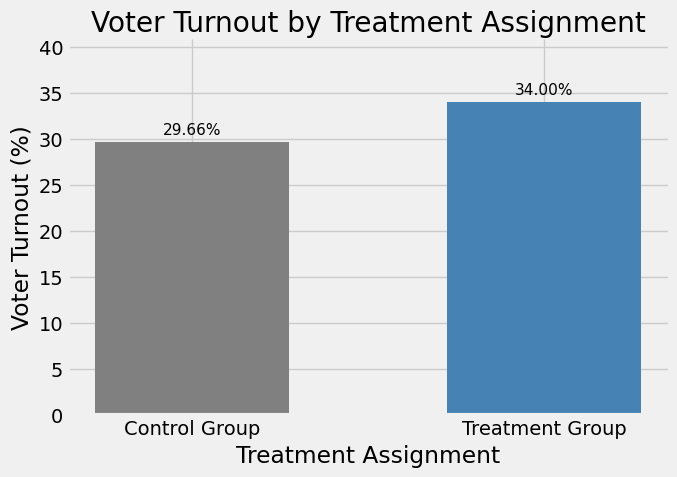

In [19]:
# Comparing voter turnout between treatment and control groups:

import pandas as pd
import matplotlib.pyplot as plt

# Creating binary indicator for receiving any treatment:
dataset["any_treatment"] = (
    dataset["treatment"].isin([1, 2, 3, 4])
).astype(int)

# Excluding observations with missing treatment or turnout:
plot_data = dataset.dropna(subset=["treatment", "voted"]).copy()

# Calculating average voter turnout by group:
turnout_summary = (
    plot_data.groupby("any_treatment")["voted"]
    .agg(["mean", "count"])
    .rename(columns={
        "mean": "Turnout Rate",
        "count": "N"
    })
)

# Converting turnout rates to percentages:
turnout_summary["Turnout Rate"] *= 100

# Labelling the groups:
turnout_summary.index = turnout_summary.index.map({
    0: "Control Group",
    1: "Treatment Group"
})

# Displaying summary table:
display(turnout_summary.round(2))

# Creating bar graph:
fig, ax = plt.subplots(figsize=(7, 5))

bars = ax.bar(
    turnout_summary.index,
    turnout_summary["Turnout Rate"],
    color=["gray", "steelblue"],
    width=0.55
)

# Adding percentage labels above bars:
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=11
    )

# Formatting graph:
ax.set_ylabel("Voter Turnout (%)")
ax.set_xlabel("Treatment Assignment")
ax.set_title("Voter Turnout by Treatment Assignment")

ax.set_ylim(0, max(turnout_summary["Turnout Rate"]) * 1.2)

# Removing unnecessary borders:
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Exporting figure for LaTeX:
plt.savefig(
    "voter_turnout_treatment_comparison.pdf",
    bbox_inches="tight"
)

plt.show()


In [27]:
# OLS Regression Excluding g2004

import pandas as pd
import statsmodels.api as sm

# Create treatment dummy variables if they do not exist
for t in range(1, 5):
    dataset[f"treatment_{t}"] = (
        dataset["treatment"] == t
    ).astype(int)

# Define predictors, excluding g2004
predictors = [
    "treatment_1",
    "treatment_2",
    "treatment_3",
    "treatment_4",
    "hh_size",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

# Define dependent and independent variables
Y = dataset["voted"]

X = dataset[predictors]
X = sm.add_constant(X)

# Estimate OLS model
OLS_No_g2004 = sm.OLS(Y, X).fit()

# Display regression summary
print(OLS_No_g2004.summary())

# Extract regression results
ols_table = pd.DataFrame({
    "Coefficient": OLS_No_g2004.params,
    "Std. Error": OLS_No_g2004.bse,
    "t-statistic": OLS_No_g2004.tvalues,
    "p-value": OLS_No_g2004.pvalues
})

# Round values
ols_table = ols_table.round(4)

# Export to LaTeX
ols_table.to_latex(
    "OLS_no_g2004_results.tex",
    index=True,
    caption="OLS Regression Results Excluding g2004",
    label="tab:ols_no_g2004",
    float_format="%.4f",
    escape=True
)

display(ols_table)


                            OLS Regression Results                            
Dep. Variable:                  voted   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     2492.
Date:                Fri, 23 Oct 2026   Prob (F-statistic):               0.00
Time:                        16:38:56   Log-Likelihood:            -2.1033e+05
No. Observations:              344084   AIC:                         4.207e+05
Df Residuals:                  344071   BIC:                         4.208e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const           5.0550      0.117     43.313      

,Coefficient,Std. Error,t-statistic,p-value
const,5.0550,0.1167,43.3132,0.0000
treatment_1,0.0249,0.0025,9.9815,0.0000
treatment_2,0.0182,0.0025,7.3014,0.0000
treatment_3,0.0805,0.0025,32.2331,0.0000
treatment_4,0.0479,0.0025,19.1627,0.0000
hh_size,0.0079,0.0010,7.6721,0.0000
g2002,0.0860,0.0022,38.8434,0.0000
g2000,-0.0259,0.0024,-10.7886,0.0000
p2004,0.1543,0.0016,98.6543,0.0000
p2002,0.1296,0.0016,79.8807,0.0000


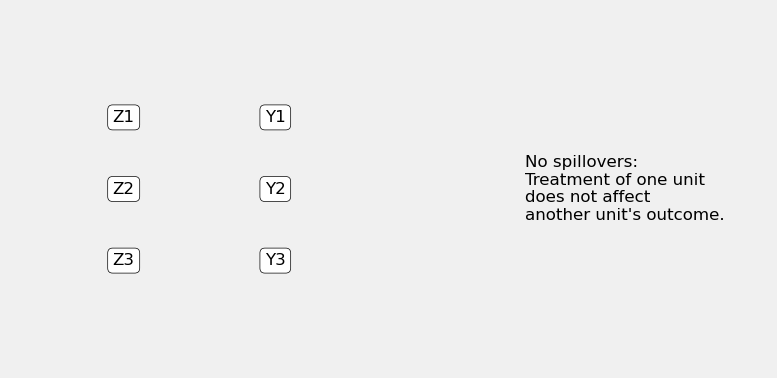

In [28]:
# Graphic for no spillovers assumption:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))

# Turn off axes
ax.axis("off")

# Positions
positions = {
    "Z1": (0.15, 0.7), "Y1": (0.35, 0.7),
    "Z2": (0.15, 0.5), "Y2": (0.35, 0.5),
    "Z3": (0.15, 0.3), "Y3": (0.35, 0.3),
}

# Draw nodes
for label, (x, y) in positions.items():
    ax.text(
        x, y, label,
        ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.3", edgecolor="black", facecolor="white"),
        fontsize=12
    )

# Draw arrows: own treatment -> own outcome only
arrows = [("Z1", "Y1"), ("Z2", "Y2"), ("Z3", "Y3")]

for start, end in arrows:
    x1, y1 = positions[start]
    x2, y2 = positions[end]
    ax.annotate(
        "",
        xy=(x2 - 0.04, y2),
        xytext=(x1 + 0.04, y1),
        arrowprops=dict(arrowstyle="->", lw=1.5)
    )

# Add note
ax.text(
    0.68, 0.5,
    "No spillovers:\nTreatment of one unit\ndoes not affect\nanother unit's outcome.",
    fontsize=12,
    va="center"
)

plt.tight_layout()
plt.savefig("sutva_no_spillovers.pdf", bbox_inches="tight")
plt.show()